In [8]:
import os
import sys
import pickle
import copy
import json
import numpy as np
import matplotlib
import matplotlib.font_manager as font_manager
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib import ticker as mticker
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

font_manager.fontManager.addfont('/storage/vsub851/plotting_styles/Inter-VariableFont_opsz,wght.ttf')
matplotlib.rcParams.update({
    'font.family': 'Inter',
    'font.weight': 'regular',
})

## Figure 4: Line plot over theseus

21


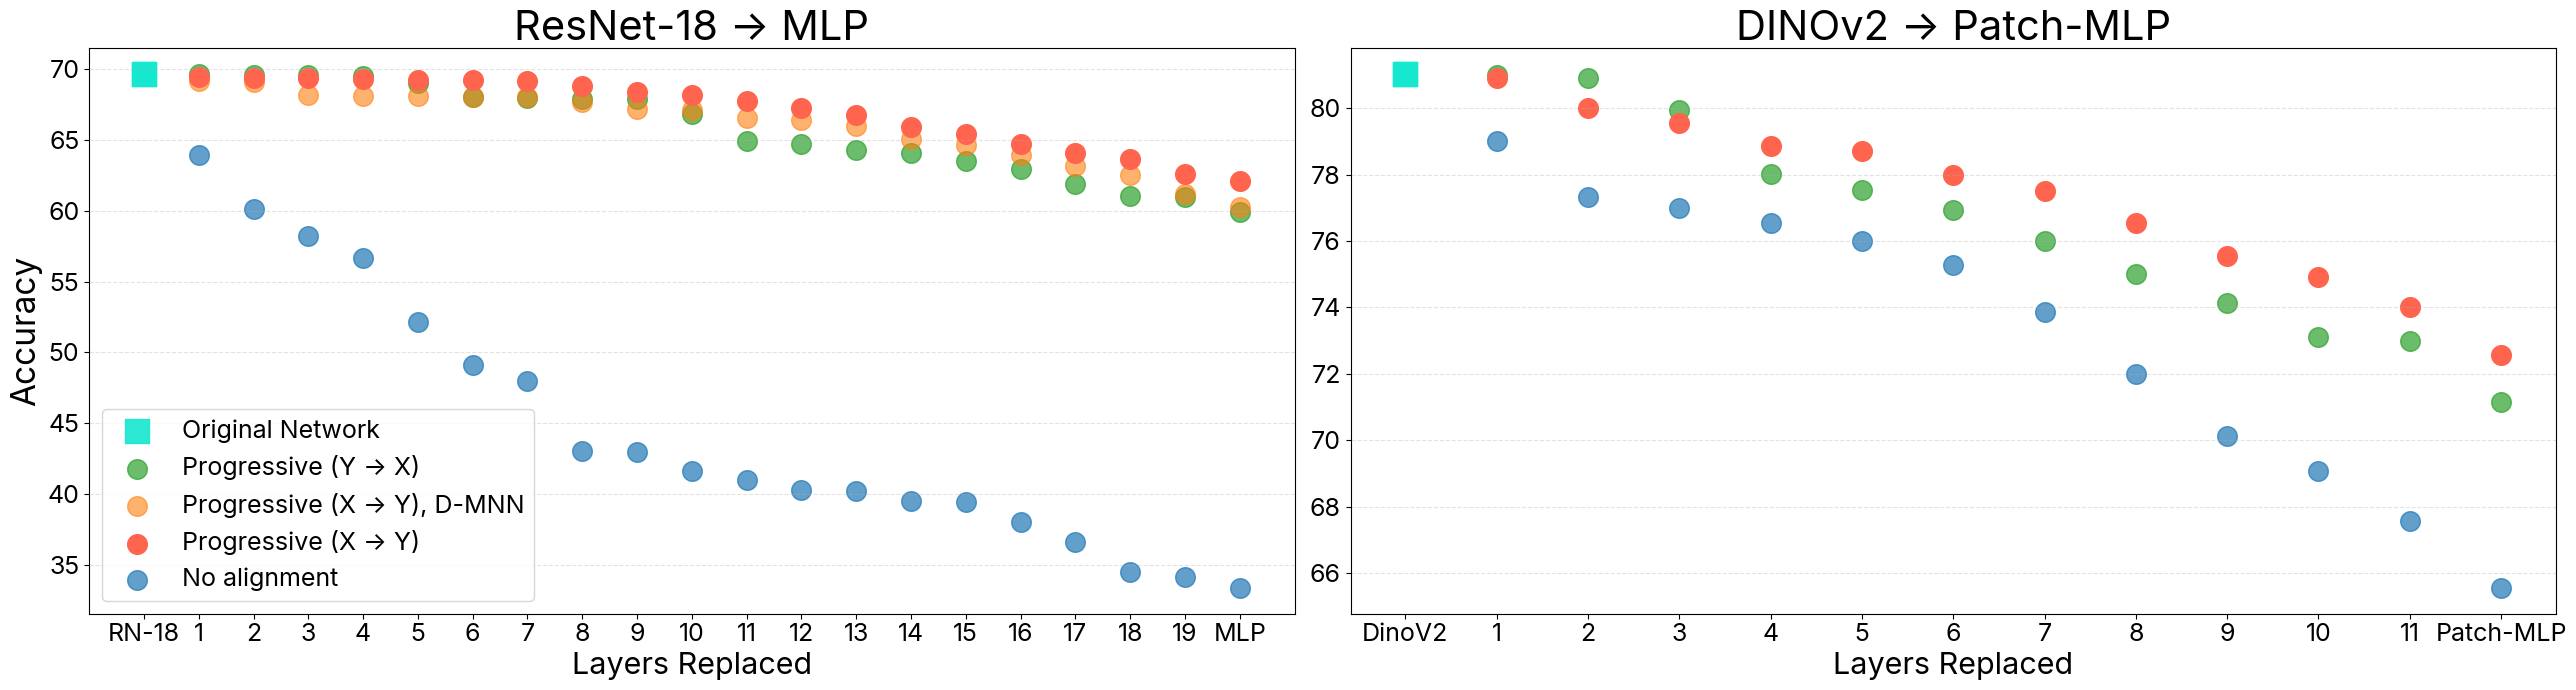

In [3]:
labels = ['RN-18', '1\nLayer', '2\nLayers', '3\nLayers', '4\nLayers', '5\nLayers', '6\nLayers', '7\nLayers', 
          '8\nLayers', '9\nLayers', '10\nLayers', '11\nLayers', '12\nLayers', '13\nLayers', '14\nLayers', '15\nLayers',
          '16\nLayers', '17\nLayers', '18\nLayers', '19\nLayers', '20\nLayers']

prog_rn18_mlp_accs = [63.52, 62.15, 61.74, 62.56, 60.65]
baseline_rn18_mlp_accs = [33.52, 34.66, 32.97, 32.91, 32.76]
baseline_accuracies = [69.66, 63.97, 60.16, 58.22, 56.69, 52.16, 49.11, 47.99, 43.01, 42.97, 41.65, 
                       41.01, 40.27, 40.20, 39.51, 39.44, 37.99, 36.61, 34.47, 34.16, 33.36]

accuracies = np.array([[69.66, 69.65, 69.62, 69.61, 69.50, 69.45, 69.42, 69.30, 68.85, 68.41, 68.31, 67.96, 67.40, 67.02, 66.06, 
               65.61, 64.99, 64.55, 64.54, 63.96, 63.51],
                       [69.66, 69.60, 69.41, 69.39, 69.39, 69.36, 69.35, 69.31, 68.99, 68.52, 68.22, 67.72, 67.44, 66.91, 66.22, 
               65.55, 64.84, 64.12, 63.47, 62.65, 62.15],
                       [69.66, 69.64, 69.61, 69.57, 69.50, 69.44, 69.37, 69.33, 68.80, 68.33, 68.32, 67.55, 67.41, 66.96, 66.10, 
               65.62, 64.97, 64.14, 63.53, 62.17, 61.74],
                       [69.66, 69.23, 69.22, 69.19, 69.18, 69.00, 68.95, 68.81, 68.80, 68.44, 68.01, 67.88, 67.56, 66.99, 66.06, 
               65.60, 64.97, 64.36, 64.30, 63.01, 62.56],
                       [69.66, 69.17, 69.12, 69.18, 69.11, 69.09, 69.06, 69.04, 68.65, 68.16, 68.11, 67.55, 66.41, 65.96, 65.10, 
               64.62, 63.97, 63.14, 62.53, 61.17, 60.65]])

std_err = np.std(accuracies, axis = 0) / accuracies.shape[0]**0.5
accuracies = np.average(accuracies, axis = 0)

accuracies_dmnn = [69.66, 69.17, 69.12, 68.18, 68.11, 68.09, 68.06, 68.04, 67.65, 67.16, 67.11, 66.55, 66.41, 65.96, 65.10, 
               64.62, 63.97, 63.14, 62.53, 61.17, 60.28]

reverse_accuracies = np.array([69.66, 69.66, 69.60, 69.60, 69.51, 69.00, 68.02, 67.99, 67.91, 67.90, 66.82, 64.96, 64.75, 64.26, 
                      64.07, 63.54, 62.98, 61.88, 61.06, 60.99, 59.94])


dinov2_labels = ['DinoV2', '1\nLayer', '2\nLayers', '3\nLayers', '4\nLayers', '5\nLayers', '6\nLayers', '7\nLayers', 
          '8\nLayers', '9\nLayers', '10\nLayers', '11\nLayers', '12\nLayers']
dinov2_accuracies = [81.03, 80.92, 80.00, 79.55, 78.87, 78.72, 78.00, 77.51, 76.55, 75.54, 74.92, 74.00, 72.56]
dinov2_reverse_accuracies = [81.03, 80.99, 80.91, 79.96, 78.01, 77.55, 76.94, 76.01, 75.00, 74.12, 73.11, 72.99, 71.14]
dinov2_baseline_accuracies = [81.03, 79.02, 77.34, 76.99, 76.53, 76.01, 75.27, 73.87, 71.99, 70.14, 69.06, 67.57, 65.55]

x = list(range(len(labels)))
print(len(x))
labels[-1] = 'MLP'
fig, axes = plt.subplots(nrows = 1, ncols = 2, dpi=100, figsize=(26, 7))

labels = [i.replace('\nLayers', '') for i in labels]
labels = [i.replace('\nLayer', '') for i in labels]

dinov2_x = list(range(len(dinov2_labels)))
dinov2_labels = [i.replace('\nLayers', '') for i in dinov2_labels]
dinov2_labels = [i.replace('\nLayer', '') for i in dinov2_labels]
dinov2_labels[-1] = 'Patch-MLP'

axes[0].scatter([x[0]], [accuracies[0]], s=300, color='#16E7CF', marker='s', alpha=0.9, label='Original Network')
axes[0].scatter(x[1:], reverse_accuracies[1:], s = 200, color = 'tab:green', alpha = 0.7, label = 'Progressive (Y → X)')
axes[0].scatter(x[1:], accuracies_dmnn[1:], s = 200, color = 'tab:orange', alpha = 0.6, label = 'Progressive (X → Y), D-MNN')
axes[0].scatter(x[1:-1], accuracies[1:-1], s=200, color='#FF644E', alpha=1, label='Progressive (X → Y)')
axes[0].scatter([x[-1]], [accuracies[-1]], s=200, color='#FF644E', alpha=1, label='_nolegend_')

# Baseline
axes[0].scatter([x[0]], [baseline_accuracies[0]], s=300, color='#16E7CF', marker='s', label='_nolegend_')
axes[0].scatter(x[1:], baseline_accuracies[1:], s=200, color='tab:blue', alpha=0.7, label='No alignment')

axes[1].scatter([dinov2_x[0]], [dinov2_accuracies[0]], s=300, color='#16E7CF', marker='s', label='_nolegend_')
axes[1].scatter(dinov2_x[1:], dinov2_reverse_accuracies[1:], s=200, color='tab:green', alpha=0.7, label='Progressive (Y → X)')
axes[1].scatter(dinov2_x[1:], dinov2_accuracies[1:], s=200, color='#FF644E', alpha=1, label='Progressive (X → Y)')

# Baseline
axes[1].scatter([dinov2_x[0]], [dinov2_baseline_accuracies[0]], s=300, color='#16E7CF', marker='s', label='Original Network')
axes[1].scatter(dinov2_x[1:], dinov2_baseline_accuracies[1:], s=200, color='tab:blue', alpha=0.7, label='No alignment')

# Labels and baseline line
axes[0].set_ylabel('Accuracy', fontsize=24)
axes[1].set_xlabel('Layers Replaced', fontsize=22)
axes[0].set_xlabel('Layers Replaced', fontsize=22)
# axes[0].axhline(accuracies[0], linestyle='--', color = 'tab:red', alpha = 0.7)
# axes[1].axhline(dinov2_accuracies[0], linestyle='--', color = 'tab:red', alpha = 0.7)

# X/Y ticks
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, fontsize=18)
axes[0].tick_params(axis='y', labelsize=18)

axes[1].set_xticks(dinov2_x)
axes[1].set_xticklabels(dinov2_labels, fontsize=18)
axes[1].tick_params(axis='y', labelsize=18)
axes[0].legend(fontsize = 18)

axes[0].set_title('ResNet-18 → MLP', fontsize = 30)
axes[1].set_title('DINOv2 → Patch-MLP', fontsize = 30)

axes[0].grid(axis='y', linestyle='--', linewidth=0.8, alpha=0.35)
axes[1].grid(axis='y', linestyle='--', linewidth=0.8, alpha=0.35)

fig.tight_layout()
fig.savefig('../figures/layerwise_performance.pdf', format = 'pdf', dpi = 500)
plt.show()

## Figure 5: Stage-Wise Representational Similarity

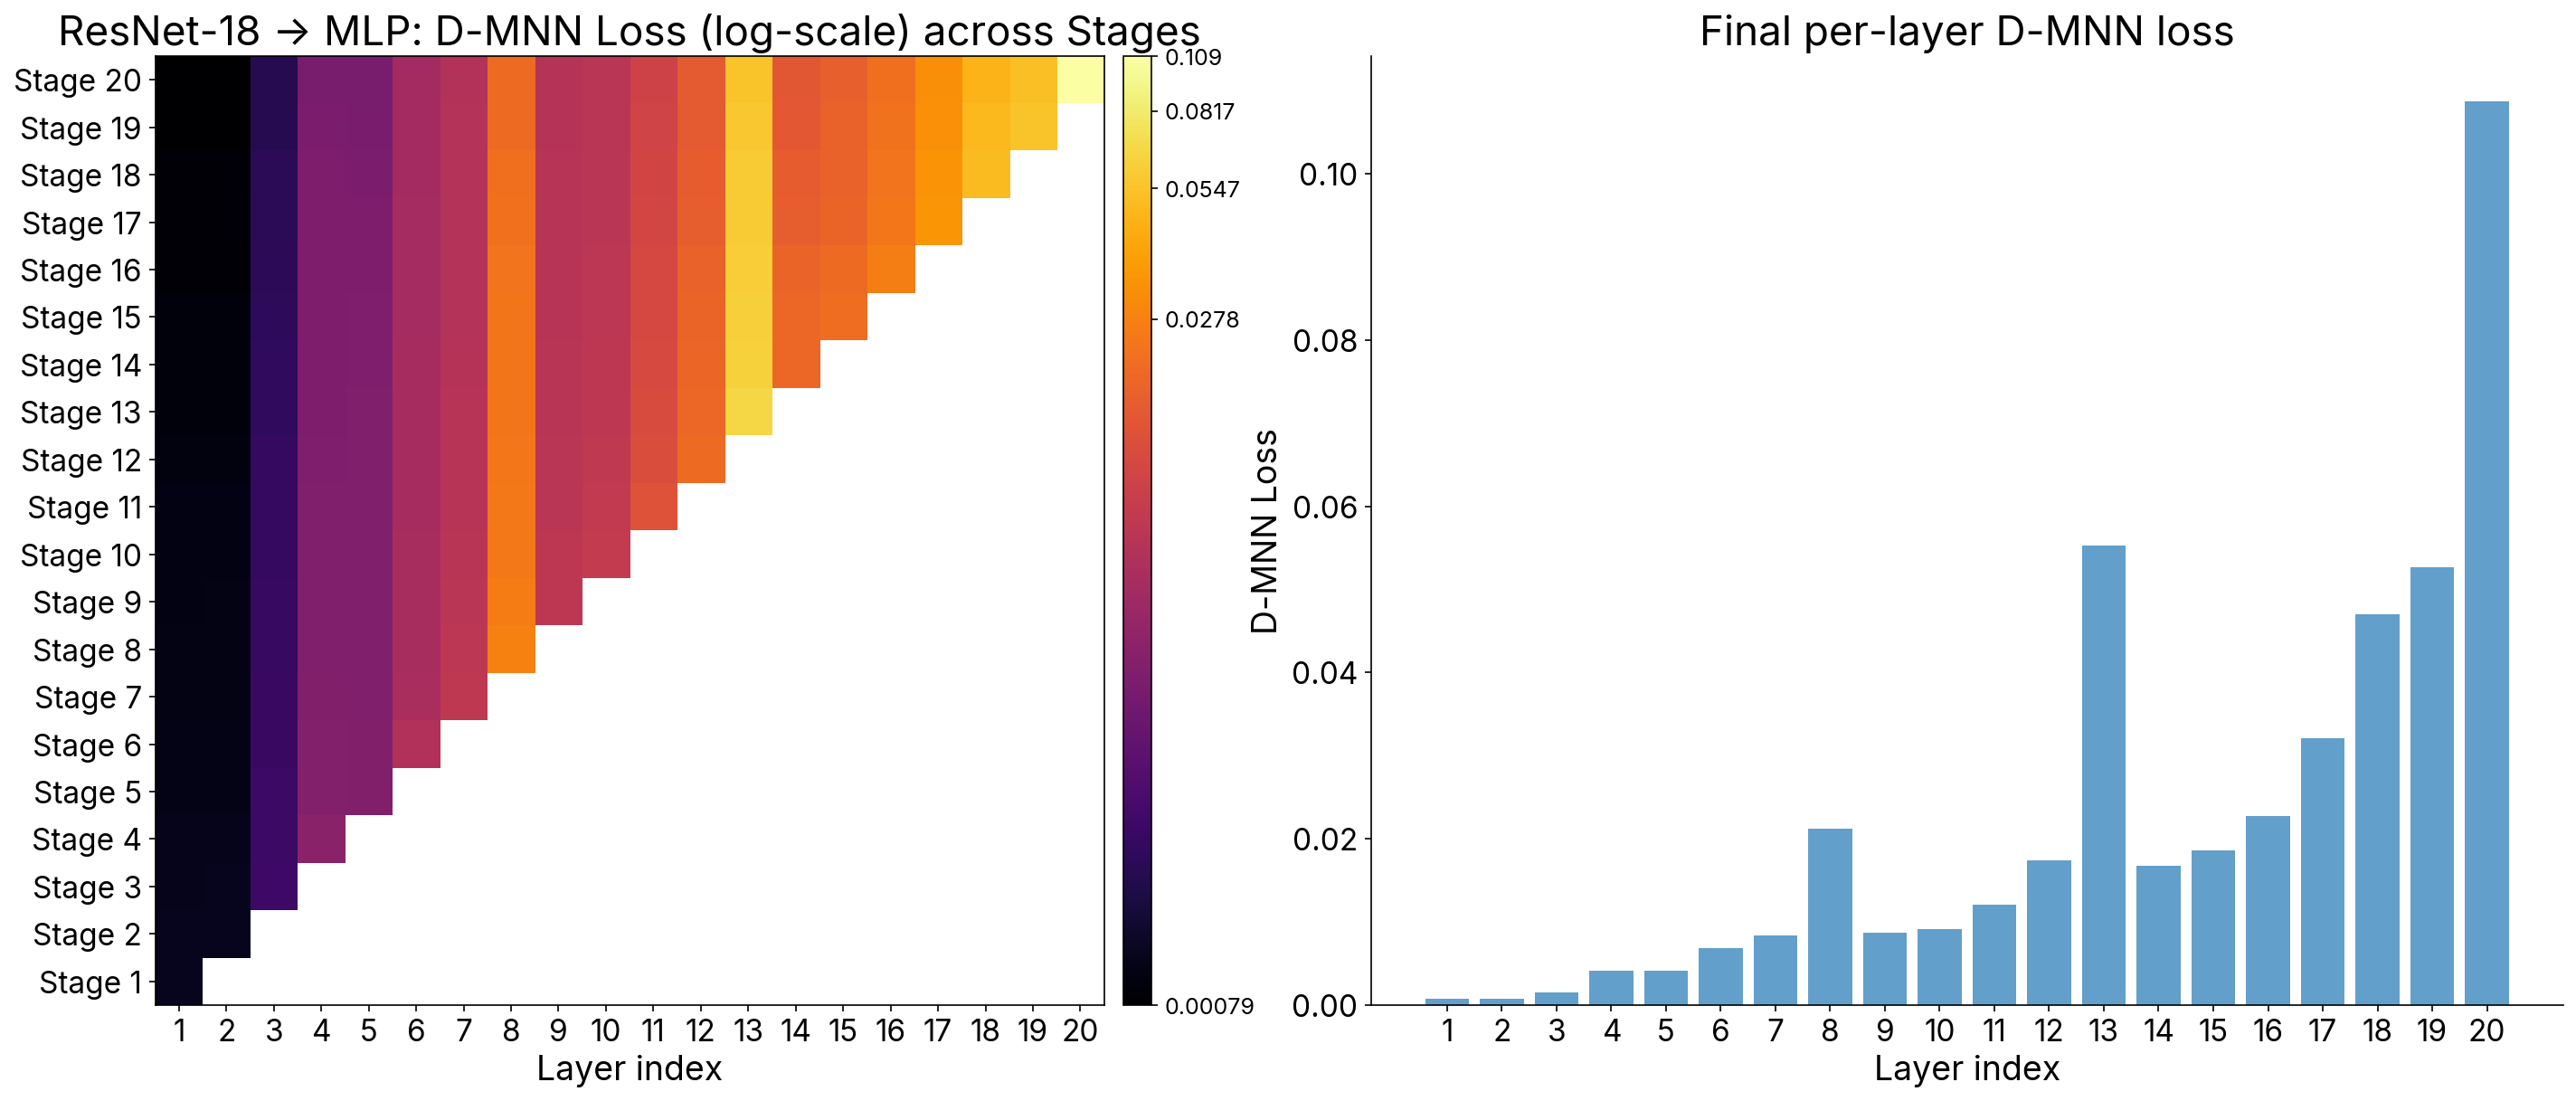

In [20]:
arr = np.load('stage_alignment_vals.npy')
arr = arr[::-1, :]
loss_vals = np.load('layer_loss_vals.npy')
with open('all_losses.json') as f:
    output_losses = json.load(f)
max_len = len(output_losses['1'])
rows_to_show = 20
start_idx = max(0, arr.shape[0] - rows_to_show)
im_data_linear = arr[start_idx:, :]

eps = 1e-12
im_data_for_img = np.log(np.clip(im_data_linear, eps, None))
im_data_for_img = np.ma.masked_invalid(im_data_for_img)

stage_labels = [f'Stage {s}' for s in range(max_len - rows_to_show + 1, max_len + 1)]  # 16..20
# stage_labels = stage_labels[::-1]

# ---- Figure ----
fig, axes = plt.subplots(ncols=2, figsize=(19, 8), dpi=150, constrained_layout=True)

# === Left: imshow ===
im = axes[0].imshow(im_data_for_img, cmap='inferno', origin='lower', aspect='auto')
axes[0].set_box_aspect(1)  # make the left panel closer to a square

# X ticks: show all integer ticks 1..num_keys
axes[0].set_xticks(np.arange(im_data_linear.shape[1]))
axes[0].set_xticklabels([str(i) for i in range(1, im_data_linear.shape[1] + 1)])
axes[0].tick_params(axis = 'x', labelsize = 16)
axes[0].xaxis.set_minor_locator(mticker.NullLocator())

# Y ticks: 'Stage 16' ... 'Stage 20'
axes[0].set_yticks(np.arange(rows_to_show))
axes[0].set_yticklabels(stage_labels)
axes[0].tick_params(axis = 'y', labelsize = 16)

axes[0].set_xlabel('Layer index', fontsize = 18)
axes[0].set_title('ResNet-18 → MLP: D-MNN Loss (log-scale) across Stages', fontsize = 22)

# Colorbar with linear labels (while image uses log values)
vmin = float(np.nanmin(np.clip(im_data_linear, eps, None)))
vmax = float(np.nanmax(np.clip(im_data_linear, eps, None)))
lin_ticks = np.linspace(vmin, vmax, 5)  # choose readable linear ticks

cax = inset_axes(
    axes[0],
    width='3%',       # width of the colorbar relative to the imshow axes
    height='100%',    # match height exactly
    loc='lower left',
    bbox_to_anchor=(1.02, 0.0, 1, 1),  # place just to the right of the axes
    bbox_transform=axes[0].transAxes,
    borderpad=0
)

cbar = fig.colorbar(im, ax=axes[0], pad=0.02, cax = cax, format='%.0e')
cbar.set_ticks(np.log(np.clip(lin_ticks, eps, None)))
cbar.ax.tick_params(labelsize = 12)
cbar.set_ticklabels([f'{t:.3g}' for t in lin_ticks])
# cbar.set_label('1 − CKA (linear scale)')

# === Right: bar plot ===
x_vals = np.arange(1, len(loss_vals)+1)
bars = axes[1].bar(x_vals, loss_vals, alpha = 0.7)  # assign to avoid printing 'BarContainer...'

# Force integer ticks and show all of them
axes[1].set_xticks(x_vals)
# axes[1].grid(axis='y', linestyle='--', linewidth=0.8, alpha=0.35)
# axes[1].xaxis.set_major_locator(mticker.MultipleLocator(1))
# axes[1].xaxis.set_minor_locator(mticker.NullLocator())

axes[1].set_xlabel('Layer index', fontsize = 18)
axes[1].set_ylabel('D-MNN Loss', fontsize = 18)
axes[1].tick_params(axis = 'x', labelsize = 16)
axes[1].tick_params(axis = 'y', labelsize = 16)
axes[1].set_title('Final per-layer D-MNN loss', fontsize = 22)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)   # base axis right spine off

# plt.savefig('../figures/dmnn_staged_alignment.png', format = 'png', dpi = 300)
plt.show()

## Figure 6: Accuracy Ablation

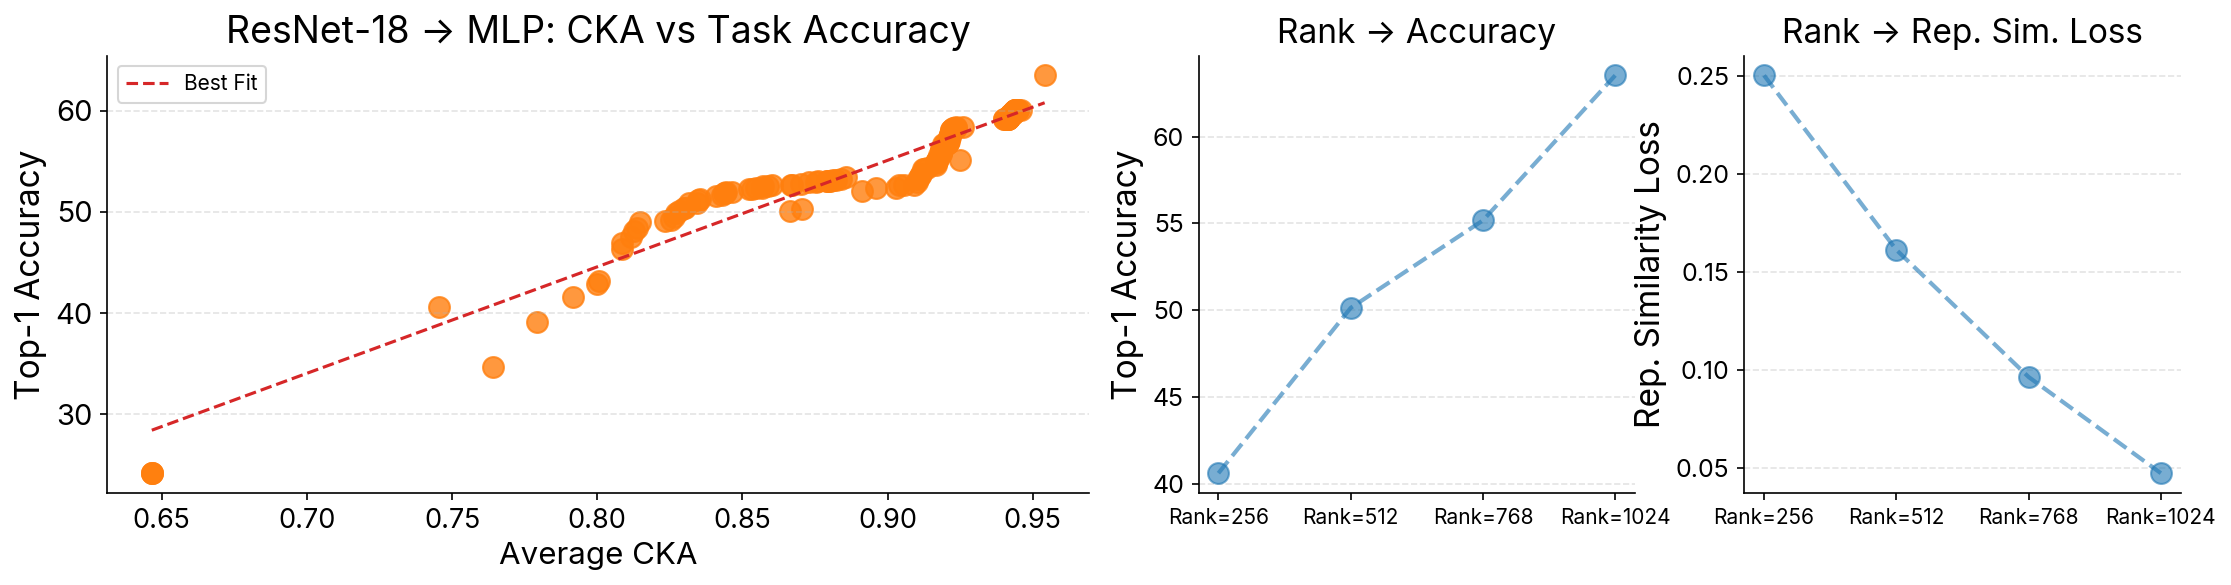

In [7]:
with open('../figures/acc_sim_data.json', 'r') as f:
    data = json.load(f)
rep_sim_losses = data['similarity']
accuracies = data['accuracies']

with open('rep_sim_losses.pkl', 'rb') as f:
    all_rep_sim_losses = pickle.load(f)
avg_rep_sim_losses = all_rep_sim_losses[0]
avg_rep_sim_losses_768 = all_rep_sim_losses[1]
avg_rep_sim_losses_512 = all_rep_sim_losses[2]
avg_rep_sim_losses_256 = all_rep_sim_losses[3]

fig, ax = plt.subplots(ncols=2, figsize=(15, 4), dpi=150)

ax[0].grid(axis='y', linestyle='--', linewidth=0.8, alpha=0.35)
ax[0].scatter(rep_sim_losses, accuracies, color='tab:orange', alpha=0.8, s=100)
ax[0].plot(
    np.unique(rep_sim_losses),
    np.poly1d(np.polyfit(rep_sim_losses, accuracies, 1))(np.unique(rep_sim_losses)),
    color='tab:red', linestyle='--', label='Best Fit'
)
ax[0].tick_params(axis='x', labelsize=13)
ax[0].tick_params(axis='y', labelsize=14)
ax[0].set_ylabel('Top-1 Accuracy', fontsize=16)
ax[0].set_xlabel('Average CKA', fontsize=15)
ax[0].set_title('ResNet-18 → MLP: CKA vs Task Accuracy', fontsize=18)
ax[0].spines[['right', 'top']].set_visible(False)
ax[0].legend()

x = ['Rank=256', 'Rank=512', 'Rank=768', 'Rank=1024']
y1 = [40.61, 50.13, 55.17, 63.52]
y2 = [avg_rep_sim_losses_256[-1], avg_rep_sim_losses_512[-1], avg_rep_sim_losses_768[-1], avg_rep_sim_losses[-1]]

# === Data for the right side ===
x = ['Rank=256', 'Rank=512', 'Rank=768', 'Rank=1024']
y1 = [40.61, 50.13, 55.17, 63.52]  # ImageNet Acc.
y2 = [avg_rep_sim_losses_256[-1], avg_rep_sim_losses_512[-1],
      avg_rep_sim_losses_768[-1], avg_rep_sim_losses[-1]]  # Rep. Sim. Loss

xticks = np.arange(len(x))

# === Split the right subplot vertically into two panels ===
# Create a 1×2 sub-gridspec inside the existing right axis, then remove it.
right_spec = ax[1].get_subplotspec().subgridspec(1, 2, wspace=0.25)
ax[1].remove()
ax_acc  = fig.add_subplot(right_spec[0])  # left panel of the right half
ax_loss = fig.add_subplot(right_spec[1])  # right panel of the right half

# --- Left panel (ImageNet Accuracy) ---
b1 = ax_acc.plot(
    xticks, y1, linewidth=2.0, alpha=0.6, linestyle = '--', marker='o', markersize = 10
)
ax_acc.set_xticks(xticks)
ax_acc.set_xticklabels(x)
ax_acc.grid(axis='y', linestyle='--', linewidth=0.8, alpha=0.35)
ax_acc.spines['top'].set_visible(False)
ax_acc.spines['right'].set_visible(False)
ax_acc.tick_params(axis='x', labelsize=10)
ax_acc.tick_params(axis='y', labelsize=12)
ax_acc.set_ylabel('Top-1 Accuracy', fontsize=16)
ax_acc.set_title('Rank → Accuracy', fontsize=16)

# --- Right panel (Representation Similarity Loss) ---
b2 = ax_loss.plot(
    xticks, y2, linewidth=2.0, alpha=0.6, linestyle = '--', marker='o', markersize = 10
)
ax_loss.set_xticks(xticks)
ax_loss.set_xticklabels(x)
ax_loss.grid(axis='y', linestyle='--', linewidth=0.8, alpha=0.35)
ax_loss.spines['top'].set_visible(False)
ax_loss.spines['right'].set_visible(False)
ax_loss.tick_params(axis='x', labelsize=10)
ax_loss.tick_params(axis='y', labelsize=12)
ax_loss.set_ylabel('Rep. Similarity Loss', fontsize=16)
ax_loss.set_title('Rank → Rep. Sim. Loss', fontsize=16)

plt.tight_layout()
# plt.savefig('../figures/accuracy_ablations.pdf', dpi = 300, format = 'pdf')